# 13. Own-model toys for the fixed learned score

Test whether the close Asimov agreement in 12 also gives similar **sampling
distributions** and global best-fit branches. Use **10,000 stat-only toys per
case and hypothesis**, at $\mu_0=0$ and $1.4$:

| Statistic | Toy generation |
|---|---|
| Fixed learned score, 36 bins | Independent Poisson counts in the fixed bins from 12 |
| Fixed learned score, 144 bins | Independent Poisson counts; resolution control |
| Analytical unbinned | Fresh continuous physical Poisson experiments, including preselection |
| Learned unbinned | Poisson resampling of the frozen selected $S$ bank with learned weights |

Every statistic is evaluated under **its own generating model**. The four
ensembles are not fits to shared pseudo-data. The score anchor stays at
$\eta=1$ for both generating hypotheses and throughout every fit:
$$
q_{\mu_0}=-2\log\frac{L(\mu_0)}{L(\widehat\mu)},\qquad
0\leq\widehat\mu\leq3.
$$
Use the full physical $\mu$ and $\sqrt\mu$ dependence, including the competing
minimum. There are no nuisance fits, one-sided truncation, template fluctuations
or retraining. Histograms and survival plots use logarithmic vertical axes.

### Run from the top after 12

Use the same run and filtered ensembles as 04/12. The completed 04 bank
supplies the cached learned ratios; 12's 36/144-bin score counts are reused.
There is no expansion beyond **10M selected events per source**, and no
ratio-network evaluation per toy.

By default, reuse matching analytical and learned unbinned toy rows from 07,
including failed fits. The notebook checks the bank, rates, normalizers,
selection, physics, reference implementation, seed and fit settings before
reusing them. It never changes 07's files. Missing reference toys are generated
in 13; a configuration mismatch stops with an explanation.

With a completed matching 07, only **40,000 new binned fits** are needed.
Without those references, there are 80,000 fits in total. A CPU runtime is
sufficient when all reference toys are reused. A GPU helps apply the frozen
selector if fresh analytical toys are needed. Those experiments are toy data,
not additional reference-bank events.

If an earlier run stopped while saving source diagnostics, reopen this updated
notebook and run from the top with the same `OUTPUT_TAG`. Its compatible
checkpoints and the completed 07 references are retained; no cache deletion
or rerun of 04/12 is needed.

In [1]:
import os
import sys
from pathlib import Path

RUN_NAME = "paper-distinct-s-v4"
MODE = os.environ.get("POODEMO_MODE", "production")  # production or smoke
CONFIG_OVERRIDES = {}  # e.g. {"quadrature_per_process": 500_000, "epochs": 150}
JAX_BACKEND = os.environ.get("POODEMO_JAX_BACKEND", "auto")  # auto, gpu, or cpu

SOURCE_COMMIT = "c06c8ab2adc5716cae3ce2c1b6265ab6ff048ab5"

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    import subprocess
    requested_backend = JAX_BACKEND.strip().lower()
    if requested_backend not in ("auto", "gpu", "cpu"):
        raise ValueError("JAX_BACKEND must be auto, gpu, or cpu")
    selected_backend = requested_backend
    if requested_backend == "auto":
        try:
            gpu_probe = subprocess.run(["nvidia-smi", "--query-gpu=name", "--format=csv,noheader"],
                                       capture_output=True, text=True, timeout=10)
            gpu_present = gpu_probe.returncode == 0 and bool(gpu_probe.stdout.strip())
        except (OSError, subprocess.TimeoutExpired):
            gpu_present = False
        selected_backend = "gpu" if gpu_present else "cpu"
    # CUDA-only selection fails visibly if initialization fails. Keep PyTorch's
    # CUDA visibility and avoid JAX reserving most GPU memory before training.
    jax_platform = "cuda" if selected_backend == "gpu" else "cpu"
    os.environ["JAX_PLATFORMS"] = jax_platform
    os.environ.setdefault("XLA_PYTHON_CLIENT_PREALLOCATE", "false")
    from google.colab import drive
    drive.mount("/content/drive", force_remount=False)
    ROOT = Path(os.environ.get("POODEMO_ROOT", f"/content/drive/MyDrive/poodemo/runs/{RUN_NAME}"))
    import tempfile
    # Download afresh even in a reused runtime; do not alter older checkouts.
    REPO_DIR = Path(tempfile.mkdtemp(prefix="poodemo-13-", dir="/content"))
    print(f"Notebook 13 source: {SOURCE_COMMIT} (fresh download)")
    if not (REPO_DIR / "pyproject.toml").exists():
        import getpass
        import io
        import shutil
        import tarfile
        import urllib.error
        import urllib.request

        archive_url = f"https://api.github.com/repos/rafaellopesdesa/poodemo/tarball/{SOURCE_COMMIT}"

        def fetch_source(token=None):
            headers = {"Accept": "application/vnd.github+json", "User-Agent": "poodemo-colab"}
            if token:
                headers["Authorization"] = "Bearer " + token
            request = urllib.request.Request(archive_url, headers=headers)
            with urllib.request.urlopen(request, timeout=180) as response:
                return response.read()

        try:
            archive_bytes = fetch_source()
        except urllib.error.HTTPError as error:
            if error.code not in (401, 403, 404):
                raise RuntimeError(f"Repository download failed (HTTP {error.code}).") from None
            token = None
            try:
                from google.colab import userdata
                token = userdata.get("GITHUB_TOKEN")
            except Exception:
                pass
            if not token:
                token = getpass.getpass("GitHub token with read access to poodemo: ").strip()
            if not token:
                raise RuntimeError("Provide a GitHub token with read access to download the pinned notebook 13 source.")
            try:
                archive_bytes = fetch_source(token)
            except urllib.error.HTTPError as auth_error:
                raise RuntimeError(f"Repository download failed (HTTP {auth_error.code}); check token access.") from None
            finally:
                token = None

        # Validate archive paths and reject links before extracting the source.
        with tempfile.TemporaryDirectory(prefix="poodemo-source-") as temp:
            staging = Path(temp).resolve()

            def safe_destination(name):
                destination = (staging / name).resolve()
                if not destination.is_relative_to(staging):
                    raise RuntimeError("Unsafe path in source archive.")
                return destination

            with tarfile.open(fileobj=io.BytesIO(archive_bytes), mode="r:gz") as archive:
                for entry in archive.getmembers():
                    safe_destination(entry.name)
                    if not (entry.isfile() or entry.isdir()):
                        raise RuntimeError("Links and special files are not supported in the source archive.")
                archive.extractall(staging)
            candidates = [p.parent for p in staging.rglob("pyproject.toml") if (p.parent / "poodemo").is_dir()]
            if len(candidates) != 1:
                raise RuntimeError("The downloaded archive must contain one poodemo repository checkout.")
            shutil.copytree(candidates[0], REPO_DIR, dirs_exist_ok=True)
        del archive_bytes

    if os.environ.get("POODEMO_SKIP_INSTALL") != "1":
        from importlib.metadata import version, PackageNotFoundError
        # JAX discovers every installed plugin, even when selecting CPU.
        # Retain already-matched CUDA 12 packages when rerunning GPU setup.
        remove_plugins = []
        for package in ("jax-cuda12-plugin", "jax-cuda12-pjrt", "jax-cuda13-plugin", "jax-cuda13-pjrt"):
            try:
                installed_version = version(package)
            except PackageNotFoundError:
                continue
            if not (selected_backend == "gpu" and package.startswith("jax-cuda12-") and installed_version == "0.5.3"):
                remove_plugins.append(package)
        if remove_plugins:
            subprocess.check_call([sys.executable, "-m", "pip", "uninstall", "-y", "-q", *remove_plugins])
        gpu_requirements = (["jax==0.5.3", "jaxlib==0.5.3",
                             "jax-cuda12-plugin[with-cuda]==0.5.3", "jax-cuda12-pjrt==0.5.3"]
                            if selected_backend == "gpu" else [])
        # Resolve with the base requirements so PyTorch's CUDA dependencies are
        # considered together with JAX's. Avoid blanket --upgrade changes.
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "-r",
                               str(REPO_DIR / "requirements-colab.txt"), *gpu_requirements])
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "-e", str(REPO_DIR)])

        # Check the live notebook kernel before any expensive network training.
        import jax
        import jaxlib
        import jax.numpy as jnp
        if jax.__version__ != "0.5.3" or jaxlib.__version__ != "0.5.3":
            raise RuntimeError("JAX packages are stale in this kernel. Restart the runtime and rerun setup.")
        if selected_backend == "gpu":
            for package in ("jax-cuda12-plugin", "jax-cuda12-pjrt"):
                if version(package) != "0.5.3":
                    raise RuntimeError(f"{package} must match JAX 0.5.3. Restart the runtime and rerun setup.")
        jax.config.update("jax_platforms", jax_platform)
        jax.config.update("jax_enable_x64", True)
        try:
            jax_devices = jax.devices()
            if not jax_devices or any(device.platform != selected_backend for device in jax_devices):
                raise RuntimeError(f"Expected {selected_backend} devices; found {jax_devices}")
            probe_value, probe_gradient = jax.jit(jax.value_and_grad(lambda x: jnp.sum(x*x)))(
                jnp.asarray([1., 2., 3.], dtype=jnp.float64))
            probe_gradient.block_until_ready()
            if (float(probe_value) != 14. or list(probe_gradient) != [2., 4., 6.]
                    or probe_gradient.dtype != jnp.float64
                    or any(device.platform != selected_backend for device in probe_gradient.devices())):
                raise RuntimeError("JAX double-precision value/gradient check failed")
        except Exception as error:
            raise RuntimeError(
                f"JAX {selected_backend} startup failed. Select a Colab GPU runtime if requesting GPU, "
                "then restart the runtime and rerun setup. Use JAX_BACKEND='cpu' only for an intentional CPU run."
            ) from error
        print(f"JAX {jax.__version__} / jaxlib {jaxlib.__version__}: backend={selected_backend}, {jax_devices}; float64 JIT/gradient OK")

    # A new editable install is not activated in an already-running kernel.
    # Expose the inner package directly, including after a failed import cached
    # the outer /content/poodemo checkout as a namespace package.
    import importlib
    source_root = str(REPO_DIR.resolve())
    if source_root in sys.path:
        sys.path.remove(source_root)
    sys.path.insert(0, source_root)
    importlib.invalidate_caches()
    # Run from the top: subsequent cells recreate objects from this checkout.
    # Clear all poodemo submodules, including old plotting and fit functions.
    for module_name in list(sys.modules):
        if module_name == "poodemo" or module_name.startswith("poodemo."):
            del sys.modules[module_name]

else:
    # Locally: pip install -r requirements-colab.txt && pip install -e .
    ROOT = Path(os.environ.get("POODEMO_ROOT", str(Path.home() / "poodemo-runs" / RUN_NAME)))
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / "poodemo" / "pipeline.py").exists():
            sys.path.insert(0, str(candidate))
            break

ROOT.mkdir(parents=True, exist_ok=True)
print(f"Run directory: {ROOT}")
print(f"Mode: {MODE}")

Mounted at /content/drive
Notebook 13 source: c06c8ab2adc5716cae3ce2c1b6265ab6ff048ab5 (fresh download)


/tmp/ipykernel_732/3212360245.py:99: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  archive.extractall(staging)


JAX 0.5.3 / jaxlib 0.5.3: backend=gpu, [CudaDevice(id=0)]; float64 JIT/gradient OK
Run directory: /content/drive/MyDrive/poodemo/runs/paper-distinct-s-v4
Mode: production


In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from poodemo.pipeline import create_run

run = create_run(ROOT, mode=MODE, overrides=CONFIG_OVERRIDES)
plt.rcParams.update({"figure.figsize": (7, 4.5), "axes.grid": True, "grid.alpha": 0.2})
display(pd.Series(run.config, name="configuration"))

,configuration
schema_version,7
mode,production
seed,20261006
physics_overrides,{}
toolkit_commit,fc09848fc6540fd32310faebbe9db6eea7ecd17b
n_per_sample,5000000
ni_sample_multiplier,10
generation_chunk,250000
preselection_train_cap,1000000
ratio_train_cap,2000000


In [3]:
MU_VALUES = (0.0, 1.4)
N_TOYS = 10_000  # Per case and per hypothesis, including in smoke mode.
BIN_COUNTS = (36, 144)
SCORE_SCALE = 0.04
EXPOSURE = 1.0
SEED = 110923  # Same reference streams as 07.
MU_BOUNDS = (0.0, 3.0)
FIT_GRID_SIZE = 129
CHECKPOINT_EVERY = 100
PROGRESS_EVERY = 100
MAX_SELECTED_PER_SOURCE = 10_000_000
REUSE_07 = True
REFERENCE_TAG = '07_signal_own_model_statonly_10M_36_9_v1'
OUTPUT_TAG = '13_fixed_score_statonly_10M_36_144_v1'
run = run.with_config(reference_ratio_denominator='S', reference_ratio_power=2.0,
    reference_ratio_eta_floor=0.0, mc_zero_max_bin=0.01, mc_zero_max_total=0.05)
print('Total requested toy rows:', len(MU_VALUES) * (len(BIN_COUNTS)+2) * N_TOYS)

Total requested toy rows: 80000


In [4]:
import os
from pathlib import Path
from poodemo.data import save_json
from poodemo.ensemble_bundle import use_bundle, BundleEvaluationRun
from poodemo.member_filter import MemberFilterPolicy, unfiltered_run
from poodemo.practical import (PracticalRun, use_practical_run,
                               reuse_filtered_ensembles as filter_ratio_ensembles)

RATIO_SOURCE = "unity"  # "drive" explicitly selects the original saved models.
UNITY_MODEL_DIR = Path(os.environ.get(
    "POODEMO_UNITY_MODEL_DIR",
    "/content/drive/MyDrive/poodemo/unity_models/paper-distinct-s-v4-unity100",
))
ENSEMBLE_FILTER_POLICY = MemberFilterPolicy(
    catastrophic_peer_factor=100.0,
)  # Match notebook 03, including any custom policy settings.

# Unwrap a previous selection so rerunning this cell never nests evaluations.
source_run = run.base_run if isinstance(run, PracticalRun) else run
source_run = unfiltered_run(source_run)
source_run = source_run.base_run if isinstance(source_run, BundleEvaluationRun) else source_run
if RATIO_SOURCE == "unity":
    if not (UNITY_MODEL_DIR / "bundle.json").is_file():
        raise FileNotFoundError(
            f"Copy the complete Unity model bundle to {UNITY_MODEL_DIR}. "
            "Expected bundle.json, campaign.json and ratios/ directly inside it. "
            "Use the same directory as notebook 03; see unity/README.md.")
    ensemble_run = use_bundle(source_run, UNITY_MODEL_DIR)
elif RATIO_SOURCE == "drive":
    ensemble_run = source_run
else:
    raise ValueError("RATIO_SOURCE must be 'drive' or 'unity'")
run = filter_ratio_ensembles(ensemble_run, policy=ENSEMBLE_FILTER_POLICY)
filter_summary = pd.read_csv(run.path("results", "ensemble_filter", "summary.csv"))
display(filter_summary)
print("Ratio source:", RATIO_SOURCE)
print("Retained ratio models:", run.path("models", "ratios"))
print("Evaluation outputs:", run.evaluation_root)
save_json(run.path("results", "reference_ratio_model_source.json"), {
    "ratio_source": RATIO_SOURCE,
    "bundle_directory": str(ensemble_run.bundle) if RATIO_SOURCE == "unity" else None,
    "campaign_id": ensemble_run.bundle_manifest["campaign_id"] if RATIO_SOURCE == "unity" else None,
    "filter_identity": run.filter_manifest["identity"],
    "filter_policy": run.filter_manifest["inputs"]["policy"],
    "evaluation_root": str(run.evaluation_root),
})

run = use_practical_run(run)
print('Practical evaluation:', run.evaluation_root)

Reusing frozen notebook-03 member selection: /content/drive/MyDrive/poodemo/runs/paper-distinct-s-v4/evaluations/paper-distinct-s-v4-unity100/1311f17de040bc40/filtered/a4a9405505b80e39


,task,original_members,retained_members,rejected_members,status,log_integral,max_point_mass,effective_fraction,log_normalization
0,SBI_over_S,100,100,0,passed,-0.000666,0.000005,0.989804,0.001621
1,B_over_S,100,100,0,passed,-0.000690,0.000005,0.987958,0.001652
2,NI_over_S,100,100,0,passed,-0.005577,0.000014,0.374248,0.007946
3,NI_up_over_NI,100,96,4,passed,0.000110,0.000012,0.412796,0.000183
4,NI_down_over_NI,100,96,4,passed,-0.000133,0.000015,0.340834,-0.000030


Ratio source: unity
Retained ratio models: /content/drive/MyDrive/poodemo/runs/paper-distinct-s-v4/evaluations/paper-distinct-s-v4-unity100/1311f17de040bc40/filtered/a4a9405505b80e39/models/ratios
Evaluation outputs: /content/drive/MyDrive/poodemo/runs/paper-distinct-s-v4/evaluations/paper-distinct-s-v4-unity100/1311f17de040bc40/filtered/a4a9405505b80e39
Practical evaluation: /content/drive/MyDrive/poodemo/runs/paper-distinct-s-v4/evaluations/paper-distinct-s-v4-unity100/1311f17de040bc40/filtered/a4a9405505b80e39/practical_v1


In [5]:
from poodemo.signal_reference import load_signal_baseline
run, samples = load_signal_baseline(run, 36, max_selected=MAX_SELECTED_PER_SOURCE,
    local_cache=Path('/content/poodemo-13-ratios') if IN_COLAB else None)
RESULT_DIR = run.path('results', OUTPUT_TAG)
FIGURE_DIR = run.path('plots', OUTPUT_TAG)
REFERENCE_DIR = run.path('results', REFERENCE_TAG) if REUSE_07 else None
print('Selected events per source:', samples['target'])
print('Optional 07 reference checkpoints:', REFERENCE_DIR)
print('13 checkpoints:', RESULT_DIR)

04 ratios verified/staged: S, 10,000,000 events
04 ratios verified/staged: SBI, 10,000,000 events
04 ratios verified/staged: B, 10,000,000 events
04 ratios verified/staged: NI, 10,000,000 events
04 ratios verified/staged: NI_up, 10,000,000 events
04 ratios verified/staged: NI_down, 10,000,000 events
Selected events per source: 10000000
Optional 07 reference checkpoints: /content/drive/MyDrive/poodemo/runs/paper-distinct-s-v4/evaluations/paper-distinct-s-v4-unity100/1311f17de040bc40/filtered/a4a9405505b80e39/practical_v1/results/colab_mc/8bfa628d6772d034e1c4/histograms/d9091abb61937f3f3881/inference_581b0fd4c797/results/07_signal_own_model_statonly_10M_36_9_v1
13 checkpoints: /content/drive/MyDrive/poodemo/runs/paper-distinct-s-v4/evaluations/paper-distinct-s-v4-unity100/1311f17de040bc40/filtered/a4a9405505b80e39/practical_v1/results/colab_mc/8bfa628d6772d034e1c4/histograms/d9091abb61937f3f3881/inference_581b0fd4c797/results/13_fixed_score_statonly_10M_36_144_v1


### Freeze the score and construct matching generators

Use precisely notebook 12's nominal-NI learned score and centering:
$$
s_1(x)=\frac{F_S+F_{SBI}-F_B}{2(F_{SBI}+F_{NI})}
-\frac{\nu_S+\nu_{SBI}-\nu_B}{2(\nu_{SBI}+\nu_{NI})},\qquad
z_1(x)=\operatorname{sigmoid}(s_1(x)/0.04).
$$
The learned fields include selected rates and frozen observable normalizers.
Use the **same fixed component histograms at every $\mu$**, and draw
$n_b\sim\mathrm{Poisson}(\lambda_b(\mu_0))$ independently. Both generator and
likelihood use the same bounded zeroing: at most 0.01 expected events per bin
and 0.05 in total. No positive floor is introduced. Larger negative yields
make a source/fit invalid and remain in the diagnostics.

The learned unbinned reference uses the same finite $S$-bank model as 07:
ratios are normalized once over that bank, not over individual toys. Draw a
Poisson event count and sample indices with replacement according to the
combined physical intensity. Integer multiplicities enter the likelihood.
Positivity is enforced over the entire bank, including unsampled points.

The analytical reference retains 07's selected-rate quadrature. Its finite
integration error remains visible through the count-mean pull; it is not an
exact integral of the neural preselection. The references are **own-model toy
ensembles from 07**, not the physical-Asimov learned curve from 03 shown in 12.

In [6]:
from poodemo.fixed_score_toys import prepare_fixed_score_toys, run_fixed_score_toys
prepared = prepare_fixed_score_toys(run, samples, mu_values=MU_VALUES,
    bin_counts=BIN_COUNTS, score_scale=SCORE_SCALE, exposure=EXPOSURE)
display(prepared['bank']['occupancy'])
display(pd.DataFrame({
    'component': ['S', 'SBI', 'B', 'NI'],
    'observable_normalizer_12': samples['normalizers'],
    'learned_toy_bank_normalizer': prepared['configuration']['reference']['learned_bank_normalizers'],
    'selected_MC_rate': prepared['learned_rates'],
    'analytical_quadrature_rate': prepared['analytic_rates'],
}))
print('Learned-bank forbidden intervals in sqrt(mu):', prepared['learned_intervals'])

Reusing completed fixed-score counts
Preparing the frozen learned S-bank reference; no ratio-network evaluation


,source,n_bins,selected,occupied_bins,endpoint_fraction,score_min,score_max,z_min,z_max
0,S,36,10000000,30,2.000000e-07,-0.169946,0.070080,0.014082,0.852206
1,SBI,36,10000000,34,6.000000e-07,-0.232681,0.176705,0.002968,0.988081
2,B,36,10000000,34,2.000000e-07,-0.277602,0.141306,0.000967,0.971603
3,NI,36,10000000,26,0.000000e+00,-0.072977,0.070001,0.138903,0.851955
4,NI_up,36,10000000,26,0.000000e+00,-0.066768,0.069995,0.158532,0.851936
5,NI_down,36,10000000,26,0.000000e+00,-0.069053,0.070036,0.151058,0.852066
6,S,144,10000000,111,0.000000e+00,-0.169946,0.070080,0.014082,0.852206
7,SBI,144,10000000,121,2.000000e-07,-0.232681,0.176705,0.002968,0.988081
8,B,144,10000000,121,1.000000e-07,-0.277602,0.141306,0.000967,0.971603
9,NI,144,10000000,103,0.000000e+00,-0.072977,0.070001,0.138903,0.851955


,component,observable_normalizer_12,learned_toy_bank_normalizer,selected_MC_rate,analytical_quadrature_rate
0,S,1.000000,1.000000,4571.280000,4564.269364
1,SBI,0.999117,0.998886,38183.511561,38159.788651
2,B,0.999094,0.998845,40041.000000,40018.263072
3,NI,0.995217,0.992827,45449.933333,45418.432927


Learned-bank forbidden intervals in sqrt(mu): []


### Run or resume the global fits

Search all allowed intervals on a 129-point grid in $\kappa=\sqrt\mu$, refine
every resolved local minimum, and check boundaries and the tested point.
The score anchor stays at 1 even when the global best fit switches branch.

Random streams depend on case, hypothesis and toy ID. Save checkpoints every
100 new toys and on an ordinary notebook interruption. Rerun this cell to
resume; increasing `N_TOYS` extends the same streams. Failed IDs are retained,
never replaced by fresh trials. Changing the scientific settings requires a
new `OUTPUT_TAG`; an input fingerprint prevents incompatible results mixing.

At $\mu_0=0$, a zero-mean bin generates zero counts exactly. The support table
also reports whether such a bin has positive expected yield at $\mu=1$.
This explains how notebook 12 can have an infinite Asimov likelihood ratio
at zero while own-model toys **generated at zero** remain well defined.
Finite-MC support zeros and positivity restrictions can still affect the
global fit, so they remain visible without smoothing or dropping bins.

In [7]:
study = run_fixed_score_toys(prepared, RESULT_DIR, reference_directory=REFERENCE_DIR,
    n_toys=N_TOYS, seed=SEED, mu_bounds=MU_BOUNDS, grid_size=FIT_GRID_SIZE,
    checkpoint_every=CHECKPOINT_EVERY, progress_every=PROGRESS_EVERY)
print('Reference reuse:', study['reference_reuse'])
display(study['sources'])
display(study['summary'])
failures = study['results'].loc[~study['results'].valid]
print('Failed fits:', len(failures))
display(failures)
print('Upper-bound fits:', int(study['results'].at_upper.sum()))
print('Detailed results:', study['output'])

Fixed score: 36 bins, mu=0: 0/10000 cached/reused
score36, mu=0: 100/10000; last toy 0.01s
score36, mu=0: 200/10000; last toy 0.01s
score36, mu=0: 300/10000; last toy 0.01s
score36, mu=0: 400/10000; last toy 0.01s
score36, mu=0: 500/10000; last toy 0.01s
score36, mu=0: 600/10000; last toy 0.01s
score36, mu=0: 700/10000; last toy 0.01s
score36, mu=0: 800/10000; last toy 0.01s
score36, mu=0: 900/10000; last toy 0.01s
score36, mu=0: 1000/10000; last toy 0.01s
score36, mu=0: 1100/10000; last toy 0.01s
score36, mu=0: 1200/10000; last toy 0.01s
score36, mu=0: 1300/10000; last toy 0.01s
score36, mu=0: 1400/10000; last toy 0.01s
score36, mu=0: 1500/10000; last toy 0.01s
score36, mu=0: 1600/10000; last toy 0.01s
score36, mu=0: 1700/10000; last toy 0.01s
score36, mu=0: 1800/10000; last toy 0.02s
score36, mu=0: 1900/10000; last toy 0.01s
score36, mu=0: 2000/10000; last toy 0.01s
score36, mu=0: 2100/10000; last toy 0.01s
score36, mu=0: 2200/10000; last toy 0.01s
score36, mu=0: 2300/10000; last toy

,source,expected_count,occupied_bins,raw_minimum,negative_bins,largest_negative,negative_total,zeroing_accepted,zeroed_bins,zeroed_total,...,case,continuous_generator,mu,exposure,bank_size,positive_mass_nodes,effective_bank_size,max_node_probability,expected_unique_nodes,note
0,independent Poisson bin counts,85490.933333,34.0,0.000000,0.0,0.000000,0.000000,True,0.0,0.000000,...,score36,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,independent Poisson bin counts,85490.933333,121.0,0.000000,0.0,0.000000,0.000000,True,0.0,0.000000,...,score144,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,fresh continuous physical Poisson process; num...,85436.696000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,analytic,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,finite_quadrature_poisson_resampling,85490.933333,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,learned,False,0.0,1.0,10000000.0,10000000.0,4.923828e+06,6.533431e-07,84755.669448,Independent Poisson experiments conditional on...
4,independent Poisson bin counts,84284.104668,34.0,-0.000734,1.0,0.000734,0.000734,True,1.0,0.000734,...,score36,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,independent Poisson bin counts,84284.111806,121.0,-0.002003,7.0,0.002003,0.007872,True,7.0,0.007872,...,score144,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,fresh continuous physical Poisson process; num...,84227.180177,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,analytic,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,finite_quadrature_poisson_resampling,84284.103935,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,learned,False,1.4,1.0,10000000.0,10000000.0,4.901925e+06,6.585876e-07,83566.217267,Independent Poisson experiments conditional on...


,mu_test,case,label,attempted,valid,failed,mean_q,se_mean_q,fraction_q_zero,fraction_at_upper,...,q68,q90,q95,q99,reused_from_07,fraction_other_branch,se_fraction_other_branch,mean_mu_hat,max_fit_zeroed_total,fits_with_zeroing
0,0.0,score36,Fixed score: 36 bins,10000,10000,0,0.615263,0.013876,0.4859,0.0,...,0.278799,2.000113,3.260965,6.532172,0,0.0365,0.001875,0.063596,0.001685,365
1,0.0,score144,Fixed score: 144 bins,10000,10000,0,0.607565,0.013458,0.4929,0.0,...,0.259213,2.013330,3.338586,6.611862,0,0.0329,0.001784,0.057293,0.018019,329
2,0.0,analytic,Analytical unbinned,10000,10000,0,0.487616,0.013592,0.5666,0.0,...,0.091474,1.419100,2.694339,7.030032,10000,0.0488,0.002154,0.086813,NaN,0
3,0.0,learned,Learned unbinned (S bank),10000,10000,0,0.558558,0.012513,0.4934,0.0,...,0.234975,1.838849,3.114451,6.100814,10000,0.0204,0.001414,0.036123,NaN,0
4,1.4,score36,Fixed score: 36 bins,10000,10000,0,1.209363,0.017458,0.0000,0.0,...,1.158225,3.314588,4.740891,8.194097,0,0.0747,0.002629,1.296102,0.001459,9250
5,1.4,score144,Fixed score: 144 bins,10000,10000,0,1.154775,0.016792,0.0000,0.0,...,1.096816,3.179654,4.527664,7.796864,0,0.0610,0.002393,1.315276,0.014463,9389
6,1.4,analytic,Analytical unbinned,10000,10000,0,1.188284,0.016940,0.0000,0.0,...,1.174586,3.211759,4.606960,8.225071,10000,0.0313,0.001741,1.390012,NaN,0
7,1.4,learned,Learned unbinned (S bank),10000,10000,0,1.104538,0.015928,0.0000,0.0,...,1.057073,2.966818,4.326894,7.277952,10000,0.0358,0.001858,1.348893,NaN,0


Failed fits: 0


,mu_test,case,toy_id,origin,n_observed,expected_count,seconds,mu_hat,nll,valid,message,at_lower,at_upper,n_evaluations,optimizer_failures,q,fit_zeroed_bins,fit_zeroed_total


Upper-bound fits: 0
Detailed results: /content/drive/MyDrive/poodemo/runs/paper-distinct-s-v4/evaluations/paper-distinct-s-v4-unity100/1311f17de040bc40/filtered/a4a9405505b80e39/practical_v1/results/colab_mc/8bfa628d6772d034e1c4/histograms/d9091abb61937f3f3881/inference_581b0fd4c797/results/13_fixed_score_statonly_10M_36_144_v1


### Test-statistic distributions and branch switching

For each generating hypothesis, compare the log-density histogram, empirical
CDF (linear scale, including the atom at zero) and logarithmic survival curve.
The horizontal $q$ axis stays linear. Also compare the global $\widehat\mu$
histogram and CDF. The line at $\widehat\mu=0.5$ is a descriptive branch split,
not a fitting restriction: the other branch is above it at truth zero and
below it at truth 1.4.

The tables include mean $q$ with its toy standard error, quantiles, mass at
zero, branch fractions with binomial errors, boundary fits, failed fits,
yield corrections and count-mean pulls. Curves are explicitly conditional on
successful fits. No asymptotic distribution is imposed. Close agreement in
12 is motivation for this test, not a guarantee of matching toy distributions
or proof that the fixed score preserves all global information.

These distributions condition on frozen learned models and finite templates;
they do not test coverage on common physical pseudo-data or training uncertainty.

fixed_score_q_mu_0


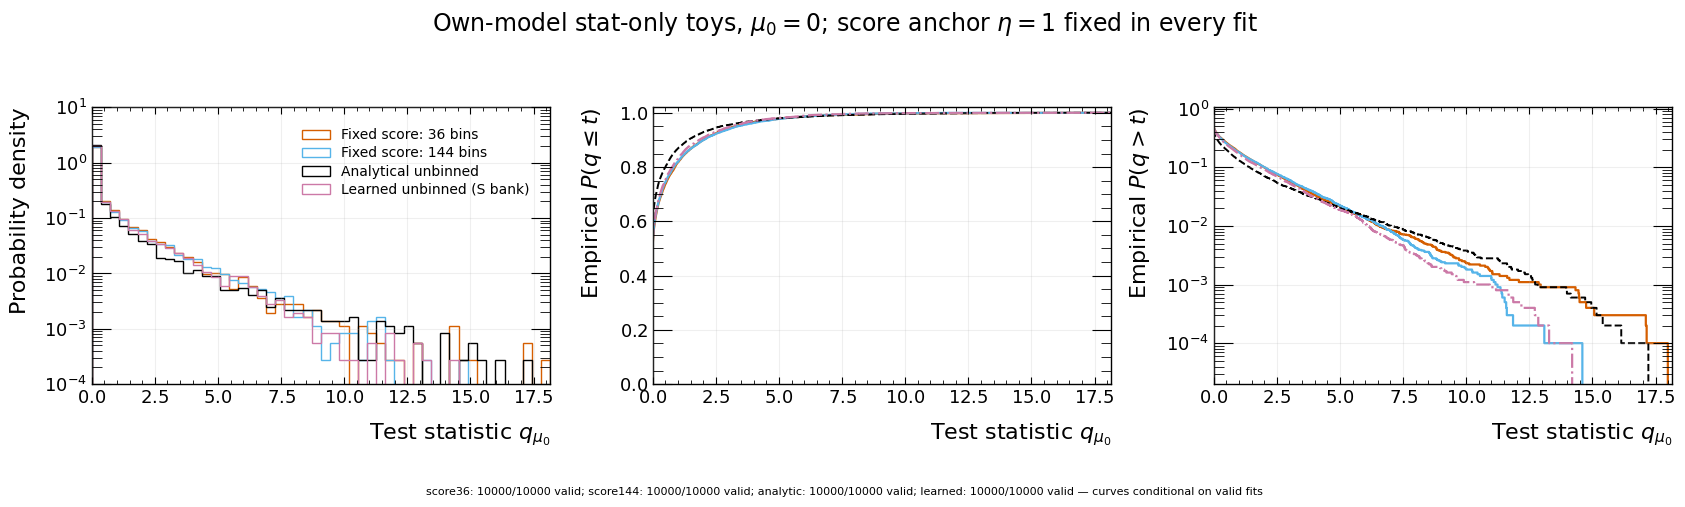

fixed_score_q_mu_1.4


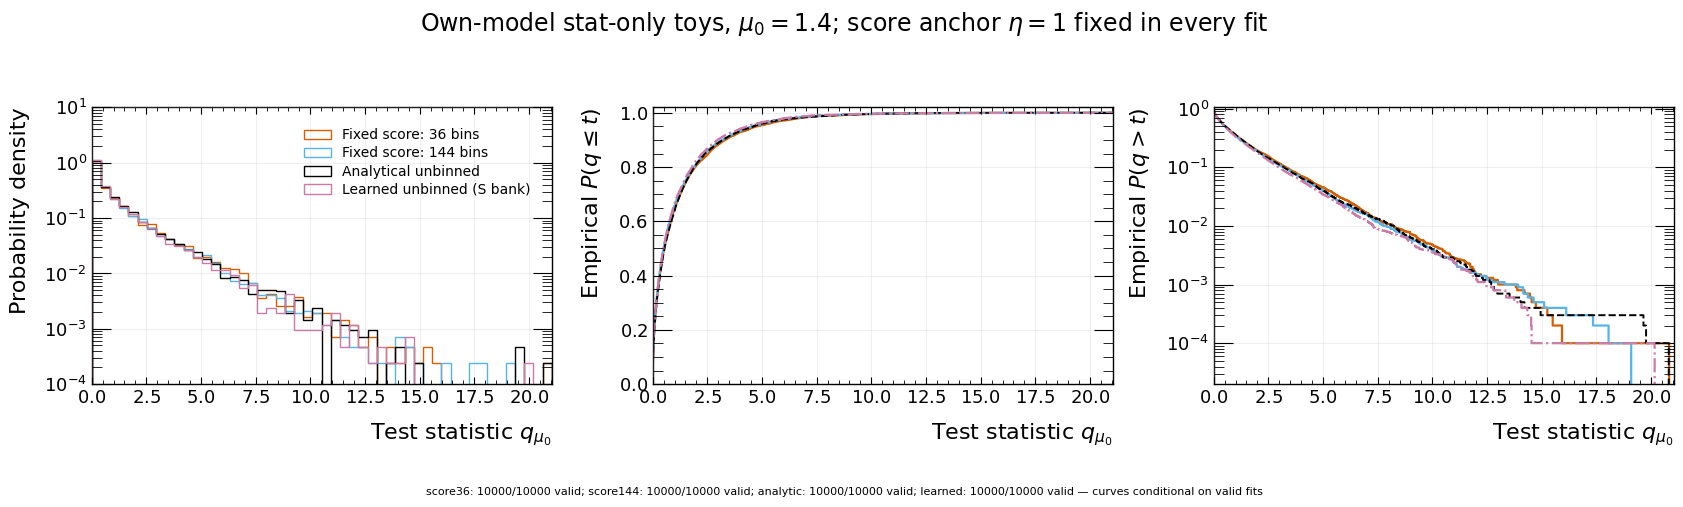

fixed_score_mu_hat_mu_0


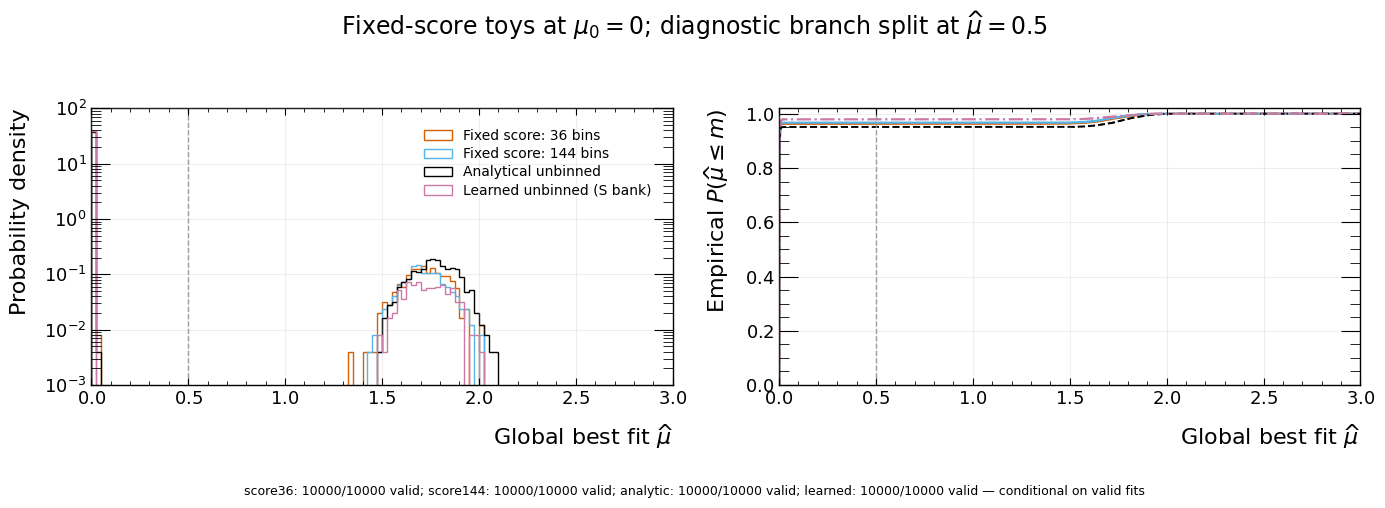

fixed_score_mu_hat_mu_1.4


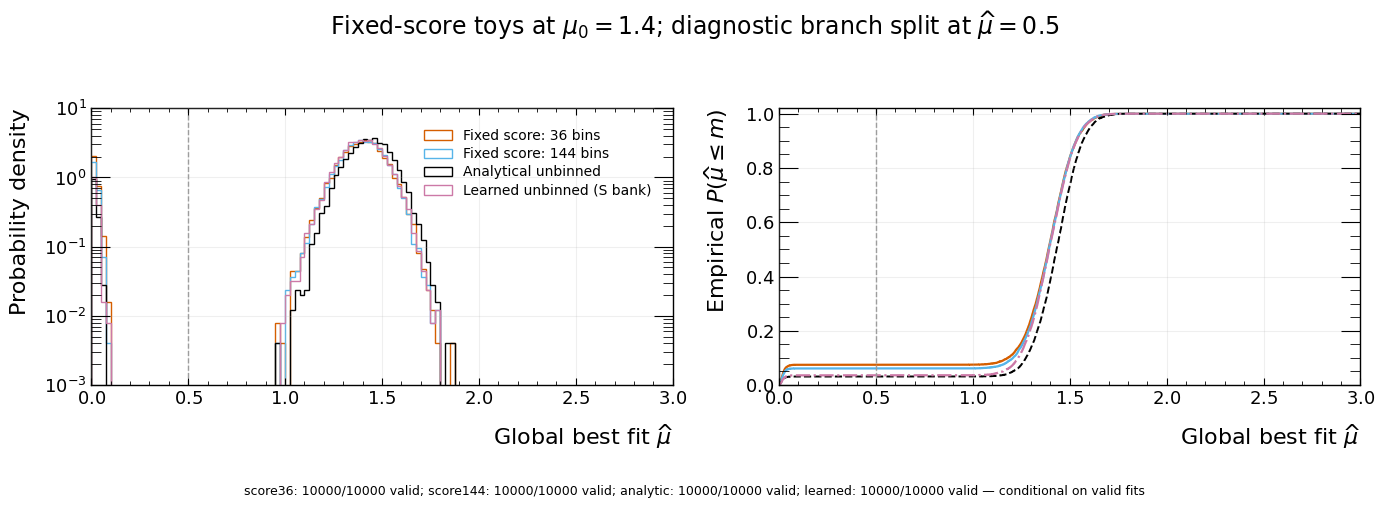

Figures: /content/drive/MyDrive/poodemo/runs/paper-distinct-s-v4/evaluations/paper-distinct-s-v4-unity100/1311f17de040bc40/filtered/a4a9405505b80e39/practical_v1/results/colab_mc/8bfa628d6772d034e1c4/histograms/d9091abb61937f3f3881/inference_581b0fd4c797/plots/13_fixed_score_statonly_10M_36_144_v1


In [8]:
from poodemo.fixed_score_toy_plots import plot_fixed_score_toys
for name, figure in plot_fixed_score_toys(study, FIGURE_DIR):
    print(name)
    display(figure)
    plt.close(figure)
print('Figures:', FIGURE_DIR)